# DSK807: Applied Machine Learning
## Lecture 8 Hands-on: Ensemble Learning

Two examples:

1. **Classification: Breast Cancer Wisconsin**
2. **Regression: Ames House Prices**

For each problem we train models one by one, inspect their performance, then compare them.

# Part 1: Classification: Breast Cancer Wisconsin

We return to the **Breast Cancer Wisconsin** dataset used in previous sessions.

The goal is to predict whether a tumor is **malignant or benign** from numerical measurements.

We evaluate each classifier using **Accuracy** and **F1-score**.


## 1. Load and split the dataset


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score


data = load_breast_cancer(as_frame=True)

df = data.frame.copy()

print("Dataset shape:", df.shape)
df.head()


features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean smoothness",
    "mean concavity"
]

X = df[features]
y = df["target"]

print("Features:")
display(X.head())

print("\nClass distribution:")
print(y.value_counts().rename(index={0: "malignant", 1: "benign"}))

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining set:", X_train.shape)
print("Test set:", X_test.shape)


Dataset shape: (569, 31)
Features:


,mean radius,mean texture,mean perimeter,mean smoothness,mean concavity
0,17.99,10.38,122.80,0.11840,0.3001
1,20.57,17.77,132.90,0.08474,0.0869
2,19.69,21.25,130.00,0.10960,0.1974
3,11.42,20.38,77.58,0.14250,0.2414
4,20.29,14.34,135.10,0.10030,0.1980



Class distribution:
target
benign       357
malignant    212
Name: count, dtype: int64

Training set: (426, 5)
Test set: (143, 5)


In [2]:
# the code here is full feature

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

data = load_breast_cancer(as_frame=True)

X = data.data.copy()
y = data.target.copy()

print("Dataset shape:", X.shape)
print("Classes:", data.target_names)
print("\nClass counts:")
print(y.value_counts().sort_index())

display(X.head())

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining set:", X_train.shape)
print("Test set:", X_test.shape)


Dataset shape: (569, 30)
Classes: ['malignant' 'benign']

Class counts:
target
0    212
1    357
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Training set: (426, 30)
Test set: (143, 30)


## 2. Logistic Regression


In [3]:
from sklearn.linear_model import LogisticRegression

lr = make_pipeline(
    MinMaxScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

lr_acc = accuracy_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print(f"Logistic Regression Accuracy: {lr_acc:.3f}")
print(f"Logistic Regression F1:       {lr_f1:.3f}")


proba = lr.predict_proba(X_train)
print(proba[-5:].round(3))


Logistic Regression Accuracy: 0.951
Logistic Regression F1:       0.962
[[0.507 0.493]
 [0.997 0.003]
 [0.961 0.039]
 [0.979 0.021]
 [0.013 0.987]]


In [4]:
# aaa = [0,1,2,3,4,5]
# print(aaa[-2:])

## 3. Support Vector Classifier


In [5]:
from sklearn.svm import SVC

svc = make_pipeline(
    MinMaxScaler(),
    SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    )
)

svc.fit(X_train, y_train)
svc_pred = svc.predict(X_test)

svc_acc = accuracy_score(y_test, svc_pred)
svc_f1 = f1_score(y_test, svc_pred)

print(f"SVC Accuracy: {svc_acc:.3f}")
print(f"SVC F1:       {svc_f1:.3f}")


SVC Accuracy: 0.979
SVC F1:       0.983


/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 4. Decision Tree


In [6]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

dt_acc = accuracy_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print(f"Decision Tree Accuracy: {dt_acc:.3f}")
print(f"Decision Tree F1:       {dt_f1:.3f}")


Decision Tree Accuracy: 0.923
Decision Tree F1:       0.938


## 5. Voting Classifier

We combine Logistic Regression, SVC, and Decision Tree using **soft voting**.


In [7]:
from sklearn.ensemble import VotingClassifier

voting = VotingClassifier(
    estimators=[
        ("lr", lr),
        ("svc", svc),
        ("dt", dt)
    ],
    voting="soft"
)

# soft voting 需要每個模型都有 predict_proba，所以你的 svc 建立時要設 SVC(probability=True)，不然 fit 會報錯。

voting.fit(X_train, y_train)
voting_pred = voting.predict(X_test)

voting_acc = accuracy_score(y_test, voting_pred)
voting_f1 = f1_score(y_test, voting_pred)

print(f"Voting Accuracy: {voting_acc:.3f}")
print(f"Voting F1:       {voting_f1:.3f}")


Voting Accuracy: 0.944
Voting F1:       0.956


/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 6. Random Forest

The Random Forest combines many Decision Trees trained on bootstrap samples and uses random feature selection at each split.

We also calculate the **out-of-bag (OOB) accuracy**.


In [21]:
from sklearn.ensemble import RandomForestClassifier


# 這是基於 decision tree 所以你也不需要作 scaling

rf = RandomForestClassifier(
    n_estimators=50, 
    max_features="sqrt", # 
    random_state=42,
    oob_score=True
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_acc = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_acc:.3f}")
print(f"Random Forest F1:       {rf_f1:.3f}")
print(f"OOB Accuracy:           {rf.oob_score_:.3f}")


# Random Forest Accuracy: 0.937
# Random Forest F1:       0.950
# OOB Accuracy:           0.934


Random Forest Accuracy: 0.951
Random Forest F1:       0.961
OOB Accuracy:           0.960


## 7. Compare all classification models


In [19]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVC",
        "Decision Tree",
        "Voting",
        "Random Forest"
    ],
    "Accuracy": [lr_acc, svc_acc, dt_acc, voting_acc, rf_acc],
    "F1": [lr_f1, svc_f1, dt_f1, voting_f1, rf_f1]
})

classification_results.round(3)


,Model,Accuracy,F1
0,Logistic Regression,0.951,0.962
1,SVC,0.979,0.983
2,Decision Tree,0.923,0.938
3,Voting,0.944,0.956
4,Random Forest,0.958,0.967


## 8. Feature Importance — Decision Tree vs. Random Forest

Compare the feature importance learned by a **single Decision Tree** with the importance aggregated across a **Random Forest**.


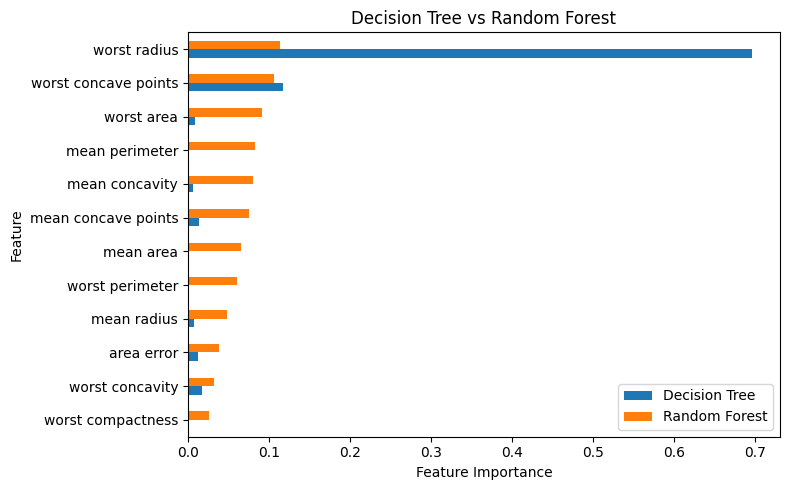

In [10]:
importance_cls = pd.DataFrame({
    "Feature": X.columns,
    "Decision Tree": dt.feature_importances_,
    "Random Forest": rf.feature_importances_
})

# Show the 12 most important features according to Random Forest
importance_cls = (
    importance_cls
    .sort_values("Random Forest", ascending=False)
    .head(12)
    .sort_values("Random Forest")
)

importance_cls.set_index("Feature").plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Feature Importance")
plt.title("Decision Tree vs Random Forest")
plt.tight_layout()
plt.show()


### Student Task — Classification

The Random Forest currently uses:

```python
n_estimators=100
```

Try:

```python
n_estimators=10
```

and:

```python
n_estimators=300
```

For each model, compare:

- Test Accuracy
- OOB Accuracy

**Question:** Does adding more trees always increase test accuracy? What happens to the OOB estimate?


# **Part 2: Regression: Ames House Prices**

We now repeat the same workflow for regression using **Ames Housing**, as in the previous Decision Tree session.

We compare:

**Linear Regression → SVR → Decision Tree → Voting → Random Forest**

Evaluation metrics:

- **MAE**
- **RMSE**
- **R²**


## 1. Load and prepare Ames Housing


In [11]:
from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ames = fetch_openml(
    name="house_prices",
    as_frame=True,
    parser="auto"
)

housing = ames.frame.copy()

features = [
    "OverallQual",   # overall material/finish quality
    "GrLivArea",     # above-ground living area
    "GarageCars",    # garage capacity
    "TotalBsmtSF",   # basement area
    "FullBath",      # full bathrooms
    "YearBuilt",     # year built
    "YearRemodAdd",  # remodeling year
    "1stFlrSF",      # first-floor area
    "TotRmsAbvGrd"   # rooms above ground
]
X_house = housing[features].copy()
y_house = housing["SalePrice"].astype(float)

print("Dataset shape:", X_house.shape)
print("\nMissing values:")
print(X_house.isna().sum())

display(X_house.head())

Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_house,
    y_house,
    test_size=0.20,
    random_state=42
)

print("\nTraining set:", Xh_train.shape)
print("Test set:", Xh_test.shape)


Dataset shape: (1460, 9)

Missing values:
OverallQual     0
GrLivArea       0
GarageCars      0
TotalBsmtSF     0
FullBath        0
YearBuilt       0
YearRemodAdd    0
1stFlrSF        0
TotRmsAbvGrd    0
dtype: int64


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,FullBath,YearBuilt,YearRemodAdd,1stFlrSF,TotRmsAbvGrd
0,7,1710,2,856,2,2003,2003,856,8
1,6,1262,2,1262,2,1976,1976,1262,6
2,7,1786,2,920,2,2001,2002,920,6
3,7,1717,3,756,1,1915,1970,961,7
4,8,2198,3,1145,2,2000,2000,1145,9



Training set: (1168, 9)
Test set: (292, 9)


## 2. Linear Regression


In [22]:
from sklearn.linear_model import LinearRegression

linear = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear.fit(Xh_train, yh_train)
linear_pred = linear.predict(Xh_test)

linear_mae = mean_absolute_error(yh_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(yh_test, linear_pred))
linear_r2 = r2_score(yh_test, linear_pred)

print(f"Linear Regression MAE:  {linear_mae:,.0f}")
print(f"Linear Regression RMSE: {linear_rmse:,.0f}")
print(f"Linear Regression R²:   {linear_r2:.3f}")


Linear Regression MAE:  24,950
Linear Regression RMSE: 39,513
Linear Regression R²:   0.796


## 3. Support Vector Regression


In [66]:
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor


svr = make_pipeline(
    StandardScaler(),
    SVR(
        kernel="rbf",
        C=1000000, # 這是懲罰 超出界現有的
        epsilon=0.1
    )
)

svr.fit(Xh_train, yh_train)
svr_pred = svr.predict(Xh_test)

svr_mae = mean_absolute_error(yh_test, svr_pred)
svr_rmse = np.sqrt(mean_squared_error(yh_test, svr_pred))
svr_r2 = r2_score(yh_test, svr_pred)

print(f"SVR MAE:  {svr_mae:,.0f}")
print(f"SVR RMSE: {svr_rmse:,.0f}")
print(f"SVR R²:   {svr_r2:.3f}")


SVR MAE:  20,290
SVR RMSE: 30,519
SVR R²:   0.879


In [55]:
from sklearn.compose import TransformedTargetRegressor

n_svr = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),                 # 標準化 X
        SVR(kernel="rbf", C=10, epsilon=0.05)
    ),
    transformer=StandardScaler()          # 標準化 y
)

n_svr.fit(Xh_train, yh_train)
n_svr_pred = n_svr.predict(Xh_test)           # 已經自動轉回原本的 y 單位

n_svr_mae = mean_absolute_error(yh_test, n_svr_pred)
n_svr_rmse = np.sqrt(mean_squared_error(yh_test, n_svr_pred))
n_svr_r2 = r2_score(yh_test, n_svr_pred)

print(f"n_SVR MAE:  {n_svr_mae:,.0f}")
print(f"n_SVR RMSE: {n_svr_rmse:,.0f}")
print(f"n_SVR R²:   {n_svr_r2:.3f}")

n_SVR MAE:  19,764
n_SVR RMSE: 29,625
n_SVR R²:   0.886


原始 SVR 的 C 和 epsilon 都跟 y 的單位綁在一起，而 y（房價）的尺度很大，導致這兩個參數失去直覺上的參考點

這代表每個訓練樣本，最多只能把預測往上或往下推 C 這麼多。對一間很貴的房子，真正跟它「像」的訓練樣本（K 接近 1 的）通常不多，這幾個樣本每個最多推 10000，加起來可能還不夠把預測從一般房價拉到它真正的價格。結果就是高價房被低估、低價房被高估，預測往中間靠。

標準化之後，每個訓練樣本一樣最多只能推 C 這麼多，機制完全沒變。標準化本身沒有解決問題，真正解決問題的是「C 相對於 y 的尺度變大了」。

原始 y 的情況

需要推的距離用房價單位算，是好幾萬甚至十幾萬。每個樣本最多推 C = 10000。上限相對於需要的距離很小，附近又只有少數幾個像它的樣本能出力，所以推不到。

標準化 y 的情況

y 的單位變成「標準差」，高價房大概只離平均值幾個標準差。每個樣本最多推 C = 10，也就是 10 個標準差。上限遠大於需要的距離，幾個樣本就綽綽有餘。

---


## 4. Decision Tree Regressor


In [82]:
from sklearn.tree import DecisionTreeRegressor

# Impute once for the tree-based models so feature importance
# remains straightforward to inspect.
house_imputer = SimpleImputer(strategy="median")

Xh_train_imp = pd.DataFrame(
    house_imputer.fit_transform(Xh_train),
    columns=Xh_train.columns,
    index=Xh_train.index
)

Xh_test_imp = pd.DataFrame(
    house_imputer.transform(Xh_test),
    columns=Xh_test.columns,
    index=Xh_test.index
)

dt_reg = DecisionTreeRegressor(
    random_state=42,
    min_samples_leaf=11,
    max_depth=6

)

dt_reg.fit(Xh_train_imp, yh_train)
dt_reg_pred = dt_reg.predict(Xh_test_imp)

dt_reg_mae = mean_absolute_error(yh_test, dt_reg_pred)
dt_reg_rmse = np.sqrt(mean_squared_error(yh_test, dt_reg_pred))
dt_reg_r2 = r2_score(yh_test, dt_reg_pred)

print(f"Decision Tree MAE:  {dt_reg_mae:,.0f}")
print(f"Decision Tree RMSE: {dt_reg_rmse:,.0f}")
print(f"Decision Tree R²:   {dt_reg_r2:.3f}")


Decision Tree MAE:  24,532
Decision Tree RMSE: 39,096
Decision Tree R²:   0.801


In [ ]:
# from sklearn.model_selection import GridSearchCV

# dt_grid = GridSearchCV(
#     DecisionTreeRegressor(random_state=42),
#     param_grid={
#         "max_depth":        [8,9,10,11,12, None],
#         "min_samples_leaf": [5, 6, 7],
#     },
#     scoring="neg_root_mean_squared_error",
#     cv=5,
# )
# dt_grid.fit(Xh_train_imp, yh_train)
# print(dt_grid.best_params_)

{'max_depth': 11, 'min_samples_leaf': 6}


## 5. Voting Regressor

For regression, the Voting Regressor combines the models by **averaging their numerical predictions**.


In [83]:
from sklearn.ensemble import VotingRegressor

voting_reg = VotingRegressor(
    estimators=[
        ("linear", linear),
        ("svr", svr),
        ("dt", make_pipeline(
            SimpleImputer(strategy="median"),
            DecisionTreeRegressor(random_state=42)
        ))
    ]
)

voting_reg.fit(Xh_train, yh_train)
voting_reg_pred = voting_reg.predict(Xh_test)

voting_reg_mae = mean_absolute_error(yh_test, voting_reg_pred)
voting_reg_rmse = np.sqrt(mean_squared_error(yh_test, voting_reg_pred))
voting_reg_r2 = r2_score(yh_test, voting_reg_pred)

print(f"Voting Regressor MAE:  {voting_reg_mae:,.0f}")
print(f"Voting Regressor RMSE: {voting_reg_rmse:,.0f}")
print(f"Voting Regressor R²:   {voting_reg_r2:.3f}")


Voting Regressor MAE:  19,980
Voting Regressor RMSE: 30,213
Voting Regressor R²:   0.881


## 6. Random Forest Regressor


max_features=1.0（小數）是比例，代表 100%，每次分裂看全部 features。這也是 RandomForestRegressor 的預設值。 0.5 是 50%。小數（例如 0.3、0.5、1.0）是比例。

max_features=1（整數）是個數，代表每次分裂只隨機抽 1 個 feature，而且只能用它來切，完全不比較。

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(
    n_estimators=200,
    max_features=0.5, # 
    random_state=42,
    oob_score=True
)

rf_reg.fit(Xh_train_imp, yh_train)
rf_reg_pred = rf_reg.predict(Xh_test_imp)

rf_reg_mae = mean_absolute_error(yh_test, rf_reg_pred)
rf_reg_rmse = np.sqrt(mean_squared_error(yh_test, rf_reg_pred))
rf_reg_r2 = r2_score(yh_test, rf_reg_pred)

print(f"Random Forest MAE:  {rf_reg_mae:,.0f}")
print(f"Random Forest RMSE: {rf_reg_rmse:,.0f}")
print(f"Random Forest R²:   {rf_reg_r2:.3f}")
print(f"OOB R²:             {rf_reg.oob_score_:.3f}")


Random Forest MAE:  18,570
Random Forest RMSE: 28,689
Random Forest R²:   0.893
OOB R²:             0.828


In [ ]:
from sklearn.model_selection import GridSearchCV

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid={
        "n_estimators": [100,120,130,140,150,200,300],
        "max_features": [1,2,3,4,5, 6, 7],
    },
    scoring="neg_root_mean_squared_error",
    cv=5,
)
rf_grid.fit(Xh_train_imp, yh_train)
print(rf_grid.best_params_)

{'max_features': 2, 'n_estimators': 200}


/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:489: FitFailedWarning: 
35 fits failed out of a total of 280.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
35 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/base.py", line 1393, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/bas

## 7. Compare all regression models


In [100]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "SVR",
        "Decision Tree",
        "Voting Regressor",
        "Random Forest"
    ],
    "MAE": [
        linear_mae,
        svr_mae,
        dt_reg_mae,
        voting_reg_mae,
        rf_reg_mae
    ],
    "RMSE": [
        linear_rmse,
        svr_rmse,
        dt_reg_rmse,
        voting_reg_rmse,
        rf_reg_rmse
    ],
    "R²": [
        linear_r2,
        svr_r2,
        dt_reg_r2,
        voting_reg_r2,
        rf_reg_r2
    ]
})

regression_results.round({
    "MAE": 0,
    "RMSE": 0,
    "R²": 3
})


,Model,MAE,RMSE,R²
0,Linear Regression,24950.0,39513.0,0.796
1,SVR,20290.0,30519.0,0.879
2,Decision Tree,24532.0,39096.0,0.801
3,Voting Regressor,19980.0,30213.0,0.881
4,Random Forest,19262.0,29498.0,0.887


## 8. Feature Importance — Decision Tree vs. Random Forest


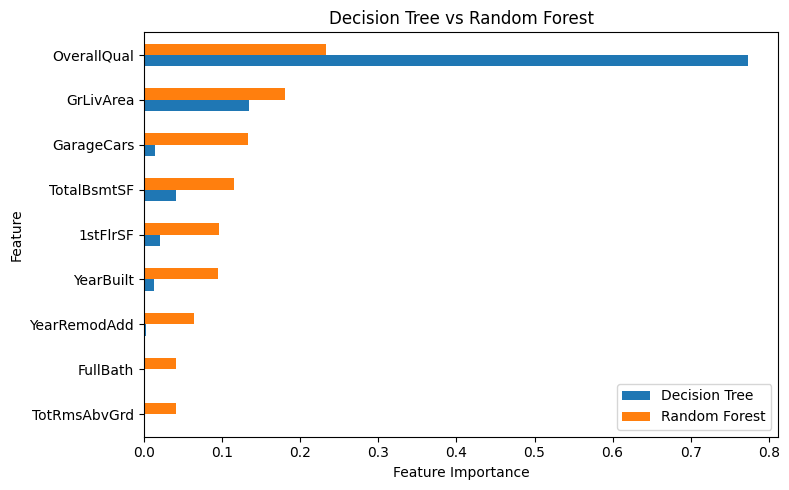

In [101]:
importance_reg = pd.DataFrame({
    "Feature": X_house.columns,
    "Decision Tree": dt_reg.feature_importances_,
    "Random Forest": rf_reg.feature_importances_
}).sort_values("Random Forest")

importance_reg.set_index("Feature").plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Feature Importance")
plt.title("Decision Tree vs Random Forest")
plt.tight_layout()
plt.show()


### Student Task — Regression

The Random Forest currently uses:

```python
max_features=1.0
```

Change it to:

```python
max_features=0.5
```

Run the Random Forest again and compare:

- RMSE
- R²
- OOB R²

**Question:** What happens when each split is allowed to consider fewer features?


# Final Discussion

Compare the two examples:

1. How did Random Forest compare with a single Decision Tree?
2. Did Voting always outperform every individual model?
3. How did the feature importances of DT and RF differ?
4. How do bootstrap sampling and random feature selection help reduce variance?
